# Simulating a BNGL model with bngsim

This notebook runs a BioNetGen model directly with [bngsim](https://github.com/lanl/bngsim): one simulation,
comparisons across parameter values, a dose scan, and local and global sensitivity analysis. The other notebooks do
the same things through the `bionetgen_tools` library.

`bngsim.Model.from_bngl` generates the reaction network with BNG2.pl and loads it. The model holds the parameters and
the current state; a `Simulator` runs it. If you know libroadrunner, the correspondence is:

| libroadrunner | bngsim |
|---|---|
| `sim[p] = v` | `model.set_param(p, v)` |
| `sim[p]` | `model.get_param(p)` |
| `sim.reset()` then `sim.simulate(0, t, n)` | `sim.run(t_span=(0, t), n_points=n, start="initial")` |
| `sim.resetAll()` | set the parameters back, then `model.reset()` |
| `res['time']`, `res[obs]` | `res.time`, `res.observables[obs]` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import bngsim

# Load model from BNGL
# NOTE: If you change the input file you may need to change simulation and output settings below
infile = "../models/fceri_starter.bngl"
model = bngsim.Model.from_bngl(infile)
sim = bngsim.Simulator(model, method="ode")

pnames = [p for p in model.primary_param_names if not p.startswith("_")]
nominal = {p: model.get_param(p) for p in pnames}
print("Parameters:", pnames)
print("Observables:", model.observable_names)

Parameters: ['Lig_tot', 'Rec_tot', 'Lyn_tot', 'kp1', 'km1', 'kp2', 'km2', 'kpL', 'kmL', 'pLb', 'dm']
Observables: ['RecDimer1', 'RecDimer2', 'LynFree', 'LynBoundU', 'BetaP1', 'BetaP2']


## Run a single simulation and plot the results

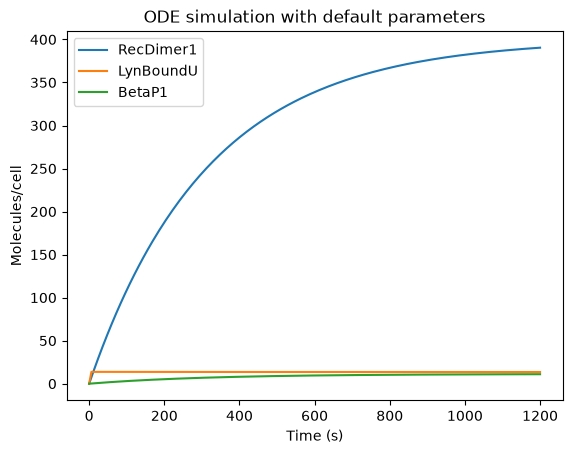

In [2]:
model.set_param("Lyn_tot", 28)
res1 = sim.run(t_span=(0, 1200), n_points=201, start="initial")

# Plot observables
for o in ["RecDimer1", "LynBoundU", "BetaP1"]:
    plt.plot(res1.time, res1.observables[o], label=o)
plt.title("ODE simulation with default parameters")
plt.xlabel("Time (s)")
plt.ylabel("Molecules/cell")
_ = plt.legend()

## Compare results of two or more simulations

Varying parameter Lig_tot, original value=6000.0


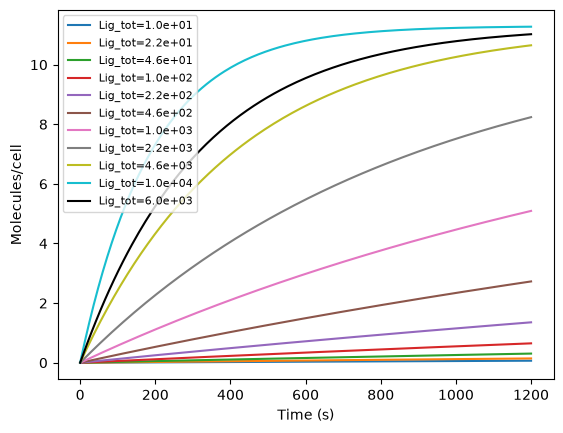

In [3]:
pname = "Lig_tot"
o = "BetaP1"
orig = model.get_param(pname)
print(f"Varying parameter {pname}, original value={orig}")
for val in np.logspace(1, 4, 10):
    model.set_param(pname, val)
    # start="initial" resets the species, recomputing seed amounts from the parameters
    res2 = sim.run(t_span=(0, 1200), n_points=201, start="initial")
    plt.plot(res2.time, res2.observables[o], label=f"{pname}={val:0.1e}")
model.set_param(pname, orig)
plt.plot(res1.time, res1.observables[o], "k", label=f"{pname}={orig:0.1e}")
plt.legend(loc="best", fontsize=8)
plt.xlabel("Time (s)")
_ = plt.ylabel("Molecules/cell")

## Scan the initial amount of Lyn and plot the steady-state value

`run_batch` runs one simulation per parameter set, in parallel threads, each from the initial conditions.

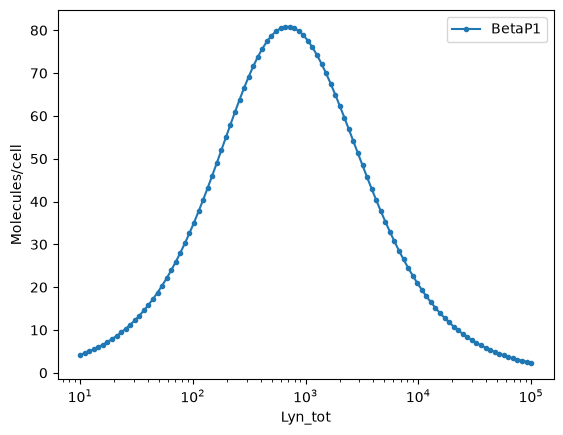

In [4]:
pname = "Lyn_tot"
o = "BetaP1"
krange = np.logspace(1, 5, 100)
model.reset()  # run_batch starts every point from the initial conditions
rows = sim.run_batch(t_span=(0, 10000), n_points=201, params=[{pname: float(k)} for k in krange])
out = [r.observables[o][-1] for r in rows]
plt.semilogx(krange, out, ".-", label=o)
plt.xlabel(pname)
plt.ylabel("Molecules/cell")
_ = plt.legend(loc="best")

# Local sensitivity analysis

bngsim computes forward sensitivities, $\partial x_i(t)/\partial p_k$, along the trajectory with CVODES. Naming the
parameters when the simulator is built gives the derivatives of every observable with respect to each of them in one
run. The normalized sensitivity is $(\partial O/\partial p)(p/O)$. The original notebook perturbed one parameter at a
time; the last cell checks the two against each other.

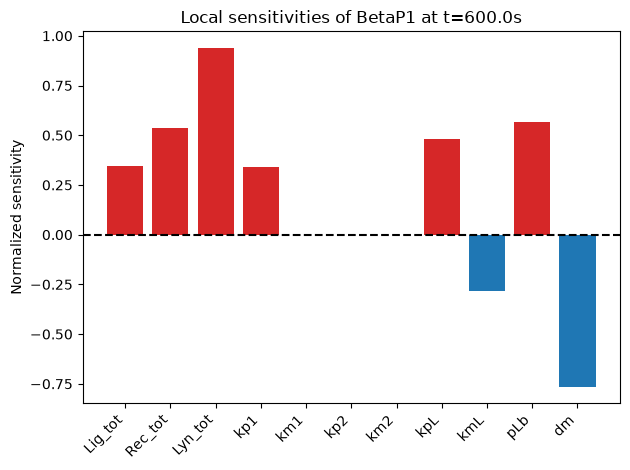

In [5]:
obs = "BetaP1"
t_end = 600; n_steps = 200

model.set_params(nominal)
sens_sim = bngsim.Simulator(model, method="ode", sensitivity_params=pnames)
res_s = sens_sim.run(t_span=(0, t_end), n_points=n_steps + 1, start="initial")

io = list(res_s.observable_names).index(obs)
O_end = res_s.observables[obs][-1]
dO = res_s.sensitivities_observables[-1, io, :]   # (n_params,) at the final time
svals = [dO[k] * model.get_param(p) / O_end for k, p in enumerate(res_s.sensitivity_params)]

colors = ["tab:blue" if s < 0 else "tab:red" for s in svals]
plt.bar(res_s.sensitivity_params, svals, color=colors)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Normalized sensitivity")
plt.title(f"Local sensitivities of {obs} at t={res_s.time[-1]:.1f}s")
plt.axhline(0, ls="--", color="k")
plt.tight_layout()

In [6]:
# Check against a one-at-a-time finite difference, as in the original notebook
x = 1e-4
tol = dict(rtol=1e-9, atol=1e-12)
base = sim.run(t_span=(0, t_end), n_points=n_steps + 1, start="initial", **tol).observables[obs][-1]
print(f"{'parameter':10s} {'analytic':>10s} {'finite diff':>12s}")
for k, p in enumerate(res_s.sensitivity_params):
    orig = model.get_param(p)
    model.set_param(p, (1 + x) * orig)
    pert = sim.run(t_span=(0, t_end), n_points=n_steps + 1, start="initial", **tol).observables[obs][-1]
    model.set_param(p, orig)
    fd = ((pert - base) / base) / x
    print(f"{p:10s} {svals[k]:10.5f} {fd:12.5f}")

parameter    analytic  finite diff
Lig_tot       0.34571      0.34567
Rec_tot       0.53888      0.53888
Lyn_tot       0.93746      0.93748
kp1           0.33934      0.33930
km1          -0.00000      0.00000
kp2           0.00002      0.00006
km2          -0.00000      0.00000
kpL           0.48269      0.48270
kmL          -0.28508     -0.28504
pLb           0.56580      0.56576
dm           -0.76338     -0.76329


# Global sensitivity analysis

Sample all parameters over ±1 order of magnitude by Latin hypercube, simulate each sample, and regress
log10(output) on log10(parameters). The regression coefficients are global sensitivity coefficients.

In [7]:
from scipy.stats import qmc
from sklearn.linear_model import LinearRegression

model.set_params(nominal)
n_params = len(pnames)
OOM = 1
lower, upper = [], []
for p in pnames:
    v = nominal[p]
    if v > 0:
        lower.append(np.log10(v) - OOM); upper.append(np.log10(v) + OOM)
    else:
        lower.append(-6); upper.append(-2)   # parameters that are 0 get a small range

n_samples = 1000
sampler = qmc.LatinHypercube(d=n_params, seed=42)
unit_samples = sampler.random(n=n_samples)
log_samples = qmc.scale(unit_samples, l_bounds=lower, u_bounds=upper)
param_samples = 10**log_samples
print(f"Sampling {n_params} parameters, {n_samples} samples; discrepancy {qmc.discrepancy(unit_samples):.4f}")

Sampling 11 parameters, 1000 samples; discrepancy 0.0050


Successful: 1000/1000
R² score: 0.8979
  Lig_tot     : +0.4111
  Rec_tot     : +0.5795
  Lyn_tot     : +0.8778
  kp1         : +0.3930
  km1         : -0.0039
  kp2         : +0.0050
  km2         : -0.0088
  kpL         : +0.4394
  kmL         : -0.2831
  pLb         : +0.5886
  dm          : -0.7555


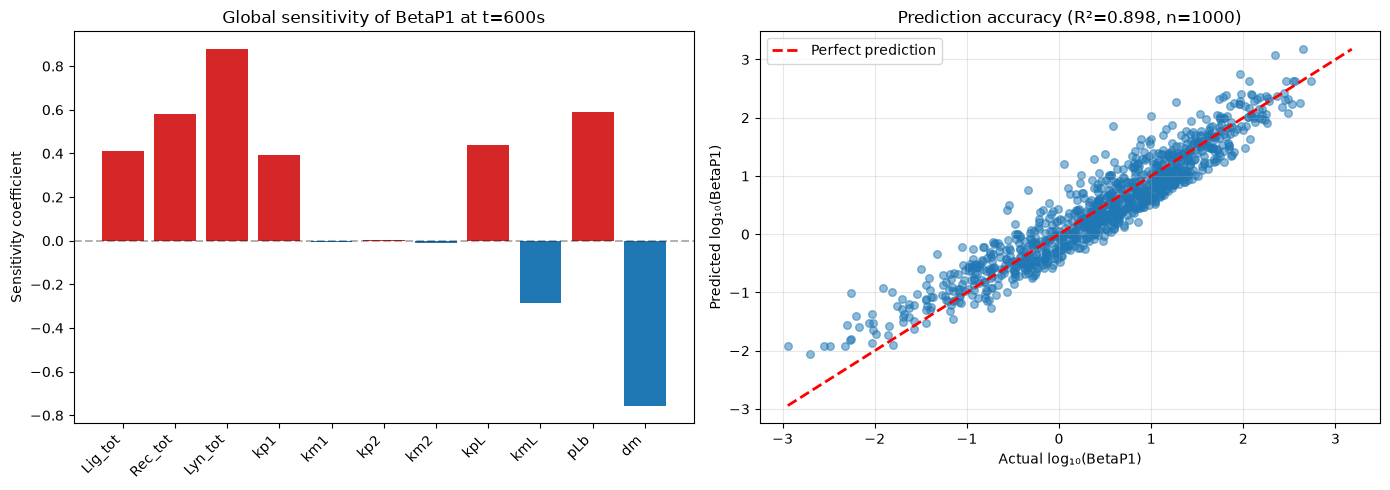

In [8]:
obs = "BetaP1"
t_end = 600

point_sets = [dict(zip(pnames, map(float, row))) for row in param_samples]
model.reset()
try:
    rows = sim.run_batch(t_span=(0, t_end), n_points=201, params=point_sets, rtol=1e-9, atol=1e-12)
    outputs = np.array([r.observables[obs][-1] for r in rows])
except bngsim.SimulationError as e:
    # One failed sample stops the batch; fall back to one at a time
    print("Batch failed, running one at a time:", str(e)[:100])
    outputs = np.full(n_samples, np.nan)
    for i, pt in enumerate(point_sets):
        model.set_params(pt)
        try:
            outputs[i] = sim.run(t_span=(0, t_end), n_points=201, start="initial").observables[obs][-1]
        except bngsim.SimulationError:
            pass
    model.set_params(nominal)

valid = np.isfinite(outputs)
print(f"Successful: {valid.sum()}/{n_samples}")
X_log = log_samples[valid]
y_log = np.log10(outputs[valid] + 1e-10)
reg = LinearRegression().fit(X_log, y_log)
sensitivity_coeffs = reg.coef_
r2_score = reg.score(X_log, y_log)
y_pred = reg.predict(X_log)
print(f"R² score: {r2_score:.4f}")
for p, c in zip(pnames, sensitivity_coeffs):
    print(f"  {p:12s}: {c:+.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(pnames, sensitivity_coeffs, color=["tab:blue" if c < 0 else "tab:red" for c in sensitivity_coeffs])
ax1.set_xticks(range(n_params)); ax1.set_xticklabels(pnames, rotation=45, ha="right")
ax1.set_ylabel("Sensitivity coefficient")
ax1.set_title(f"Global sensitivity of {obs} at t={t_end}s")
ax1.axhline(0, ls="--", color="k", alpha=0.3)
ax2.scatter(y_log, y_pred, alpha=0.5, s=30)
lo, hi = min(y_log.min(), y_pred.min()), max(y_log.max(), y_pred.max())
ax2.plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction")
ax2.set_xlabel(f"Actual log₁₀({obs})"); ax2.set_ylabel(f"Predicted log₁₀({obs})")
ax2.set_title(f"Prediction accuracy (R²={r2_score:.3f}, n={valid.sum()})")
ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# A stochastic simulation

The same model runs by Gillespie's SSA with `method="ssa"`. A seed makes the run reproducible.

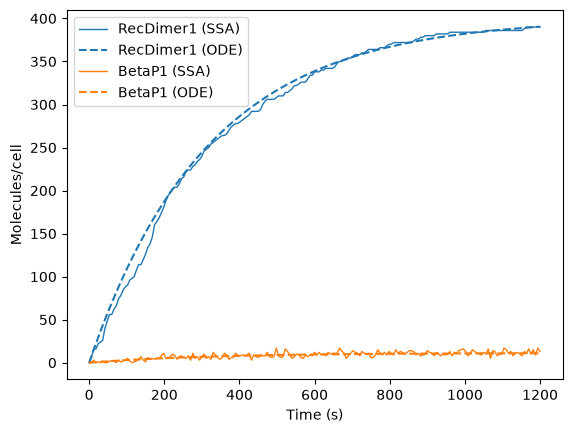

In [9]:
model.set_params(nominal)
model.reset()  # SSA checks the state it is built on: start from the (integer) initial amounts
ssa = bngsim.Simulator(model, method="ssa")
res_ssa = ssa.run(t_span=(0, 1200), n_points=201, seed=1, start="initial")
res_ode = sim.run(t_span=(0, 1200), n_points=201, start="initial")
for o in ["RecDimer1", "BetaP1"]:
    line, = plt.plot(res_ssa.time, res_ssa.observables[o], lw=1, label=f"{o} (SSA)")
    plt.plot(res_ode.time, res_ode.observables[o], "--", color=line.get_color(), label=f"{o} (ODE)")
plt.xlabel("Time (s)"); plt.ylabel("Molecules/cell")
_ = plt.legend()